# Missingness-aware gated fusion: controlled experiment
Profile/behavioral 48 + temporal-statistics 16 + scaled GCN 32. Compare concatenation (7,441 parameters) with three user-dependent gates (7,741 parameters). Gates are 2*sigmoid(Linear(99,3)), zero initialized, multiplied by availability. No softmax competition; absence cannot increase the other gates through renormalization.
This is a matched-input/training comparison, not an exact parameter-matched ablation. All profile/behavioral blocks must be available; temporal and graph absence are supported explicitly. No text encoder, contrastive loss, test evaluation, threshold tuning or automatic promotion.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/gated_fusion_v1.json').exists())
sys.path.insert(0, str(ROOT))
from src.gated_fusion import run, verify
output_dir = run(ROOT)
print('OUTPUT_VERSION:', output_dir)
print(verify(ROOT, output_dir))

C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\env\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Training concat, seed 42


concat seed 42, epoch 10: validation BCE 0.5941


concat seed 42, epoch 20: validation BCE 0.6007


concat seed 42, epoch 30: validation BCE 0.6336


...

gated seed 44, epoch 30: validation BCE 0.6121


gated seed 44, epoch 40: validation BCE 0.6112


gated seed 44, epoch 50: validation BCE 0.6866


OUTPUT_VERSION: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\results\versions\gated_fusion_v1\20260922T104310152569Z_0f07576a


{'checkpoints_reloaded': 12, 'keyed_validation_files': 12, 'keyed_gate_files': 24, 'test_inputs_parsed': 0}


## Prespecified protocol
Six new runs: concatenation and gated fusion, seeds 42/43/44, 50 epochs, identical shared initialization and minibatch order, weighted BCE (540/131), AdamW 0.001 / 0.0001, batch 32. Select earliest minimum unweighted validation BCE; also save final checkpoints. Threshold 0.5. The concatenation runs must reproduce frozen scaled-GCN checkpoints exactly.
Validation: all 144 users, graph-covered 42 and unavailable 102. Primary comparison: gated minus concatenation Bot F1; also precision, recall, ROC-AUC, AP, Brier and per-seed effects. Report gate distributions and saturation; weights are not causal feature importance. Keep the frozen temporal reference as context. Three seeds are not population uncertainty; seven covered validation bots limit conclusions.

,arm,policy,cohort,bot_f1_mean,bot_f1_std,bot_precision_mean,bot_precision_std,bot_recall_mean,bot_recall_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,brier_mean,brier_std
0,concat,best_unweighted_validation_loss,all,0.431427,0.036602,0.339141,0.033336,0.595238,0.054554,0.762418,0.010852,0.531423,0.004064,0.188248,0.007005
1,concat,best_unweighted_validation_loss,graph_available,0.492470,0.068912,0.478355,0.105574,0.523810,0.082479,0.835374,0.024603,0.661752,0.020246,0.120218,0.007169
2,concat,best_unweighted_validation_loss,graph_unavailable,0.417204,0.029799,0.314870,0.023829,0.619048,0.047619,0.731139,0.019887,0.511810,0.018613,0.216260,0.008230
3,concat,last,all,0.388969,0.023649,0.298421,0.024381,0.559524,0.020620,0.718904,0.000924,0.491206,0.017595,0.212780,0.009709
4,concat,last,graph_available,0.398684,0.023054,0.347222,0.024056,0.476190,0.082479,0.767347,0.010799,0.581652,0.043232,0.145802,0.016906
5,concat,last,graph_unavailable,0.385939,0.028939,0.287509,0.025603,0.587302,0.027493,0.694102,0.004715,0.467466,0.032318,0.240360,0.010204
6,gated,best_unweighted_validation_loss,all,0.417933,0.031090,0.329892,0.030089,0.571429,0.035714,0.752053,0.000775,0.530646,0.012254,0.190549,0.008403
7,gated,best_unweighted_validation_loss,graph_available,0.468661,0.028454,0.487879,0.118647,0.476190,0.082479,0.832653,0.010799,0.649136,0.004643,0.118207,0.010336
8,gated,best_unweighted_validation_loss,graph_unavailable,0.406280,0.033636,0.306349,0.024436,0.603175,0.054986,0.720361,0.010877,0.503606,0.004238,0.220337,0.007608
9,gated,last,all,0.409333,0.021187,0.313178,0.030983,0.595238,0.020620,0.719007,0.003825,0.476631,0.032394,0.215774,0.019366


,seed,policy,cohort,delta_bot_f1,delta_bot_precision,delta_bot_recall,delta_roc_auc,delta_average_precision,delta_brier
0,42,best_unweighted_validation_loss,all,-0.014577,-0.007204,-0.035714,-7.697044e-03,0.009172,0.004258
1,42,best_unweighted_validation_loss,graph_available,0.000000,0.000000,0.000000,-1.632653e-02,-0.033911,0.006476
2,42,best_unweighted_validation_loss,graph_unavailable,-0.019048,-0.009740,-0.047619,-6.466784e-03,0.004400,0.003345
3,42,last,all,0.009852,0.002421,0.035714,1.539409e-03,0.002907,0.001862
4,42,last,graph_available,0.049536,0.066667,0.000000,4.081633e-02,-0.010320,-0.009491
5,42,last,graph_unavailable,0.002198,-0.007421,0.047619,-4.703116e-03,-0.011489,0.006537
6,43,best_unweighted_validation_loss,all,-0.020351,-0.013298,-0.035714,-2.155172e-02,-0.017586,-0.001159
7,43,best_unweighted_validation_loss,graph_available,-0.071429,0.028571,-0.142857,-4.081633e-03,-0.008567,-0.013103
8,43,best_unweighted_validation_loss,graph_unavailable,-0.007168,-0.008130,0.000000,-2.233980e-02,-0.028561,0.003760
9,43,last,all,0.016848,0.021295,0.000000,-3.386700e-03,-0.039268,-0.007754


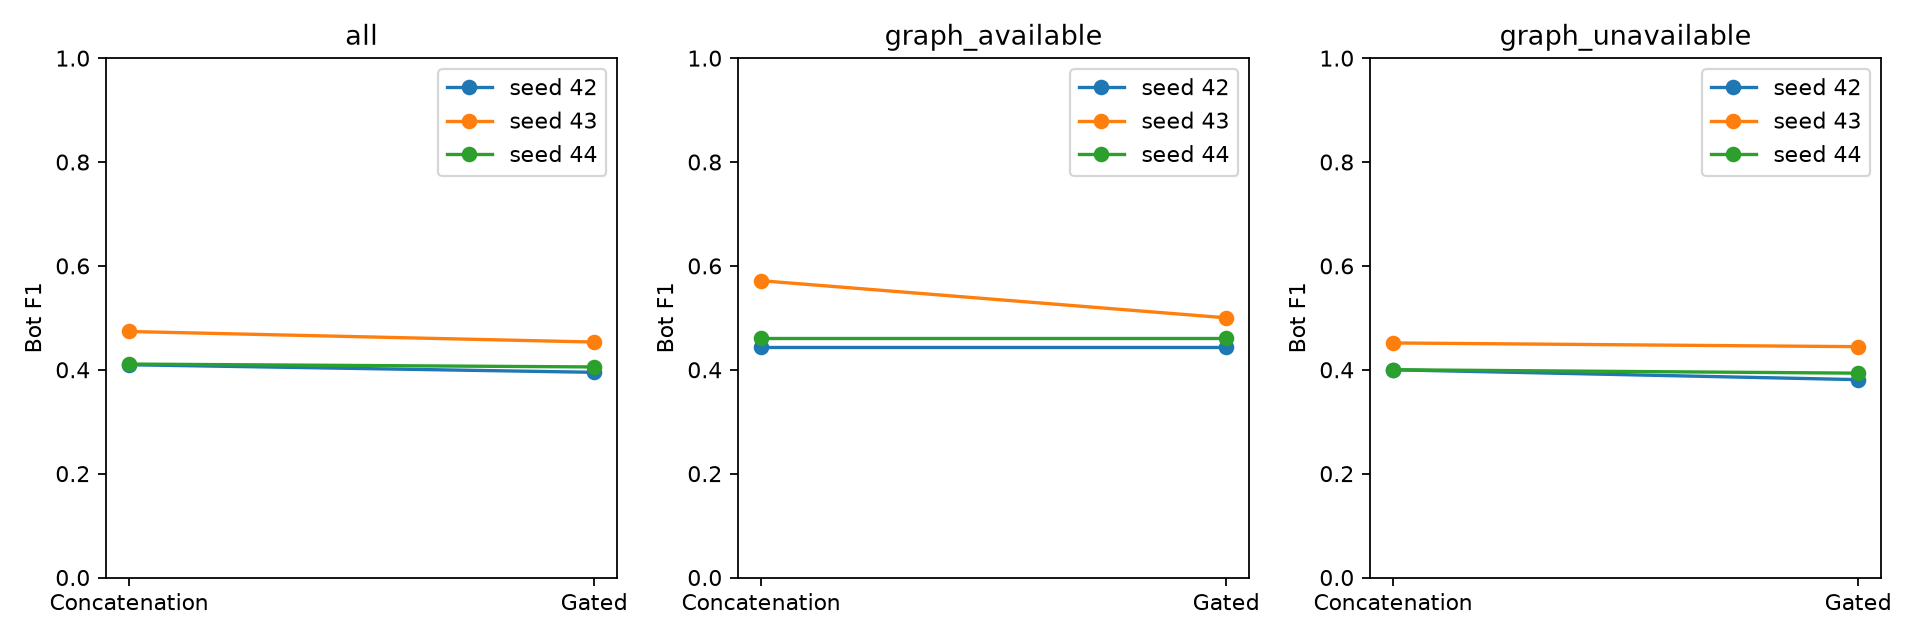

In [2]:
import pandas as pd
from IPython.display import Image, display
summary = pd.read_csv(output_dir / 'seed_summary.csv')
display(summary)
display(pd.read_csv(output_dir / 'paired_effects.csv'))
display(Image(filename=str(output_dir / 'figures/paired_f1.png')))

In [3]:
display(pd.read_csv(output_dir / 'graph_coverage.csv'))
for path in sorted((output_dir / 'gates').glob('gated*best*validation.csv')):
    print(path.name)
    frame = pd.read_csv(path)
    display(frame.groupby('has_graph')[['other_gate', 'temporal_gate', 'graph_gate']].agg(['min', 'median', 'max']))

,split,canonical_users,graph_available,graph_unavailable,graph_nodes,observed_directed_edges,eligible_bots,forbidden_gold_endpoints
0,train,671,193,478,42954,60924,31,0
1,validation,144,42,102,11436,13006,7,0


gated_seed42_best_unweighted_validation_loss_validation.csv


other_gate                     temporal_gate                      \
                 min    median       max           min    median       max   
has_graph                                                                    
0           1.304135  1.478980  1.718863      0.635641  0.974626  1.192875   
1           1.773078  1.836028  1.932534      0.571632  0.957062  1.238363   

          graph_gate                     
                 min    median      max  
has_graph                                
0           0.000000  0.000000  0.00000  
1           0.594679  0.788913  1.12612

gated_seed43_best_unweighted_validation_loss_validation.csv


other_gate                     temporal_gate                      \
                 min    median       max           min    median       max   
has_graph                                                                    
0           1.314037  1.508240  1.905082      1.259437  1.493955  1.941263   
1           1.837292  1.899777  1.954783      1.235571  1.458141  1.761261   

          graph_gate                      
                 min    median       max  
has_graph                                 
0           0.000000  0.000000  0.000000  
1           0.615935  0.834959  1.063062

gated_seed44_best_unweighted_validation_loss_validation.csv


other_gate                     temporal_gate                      \
                 min    median       max           min    median       max   
has_graph                                                                    
0           1.377212  1.606414  1.910121      0.893586  1.384500  1.774180   
1           1.920129  1.959045  1.986037      1.242122  1.515896  1.676266   

          graph_gate                      
                 min    median       max  
has_graph                                 
0           0.000000  0.000000  0.000000  
1           0.456169  0.663529  1.160038